# Compare notebook 05 populations

This report compares a named experiment with its recorded baseline. Start with the [experiment index](../docs/pilot_experiments.md). **Run All is read-only: it does not train, load models, use the GPU, or rerun simulations.** Use the project `.venv` kernel. Rerun it to refresh results while training continues, then save the notebook to retain its tables and embedded plots.

Choose `EXPERIMENT` below from `configs/pilot_experiments.json`, or override `EXPERIMENT_JOB` to inspect another prepared experiment. Its recorded plan supplies the baseline and training directories. Experiments run separately; this report never starts or resumes them.

The tables and plots use the same recorded metrics as notebook 05: checkpoint selection, test competence, behaviour, skill fractions, common validation reward components, learning curves, clean-win intervals and behaviour scatter. Results appear only when a pilot finishes training and testing; partial learning curves are labelled.

The original test has already informed this experiment, so it is now a **development comparison**. The separate **fresh confirmation** section becomes available after both populations have been evaluated on the predeclared new cases. Neither report changes checkpoints.


Set `BVR_COMPARISON_EXPORT=1` before running the report to also export its figures as PNG and PDF under the experiment's `plots/` directory. The default reads results without exporting files; neither mode changes training artifacts.


In [1]:
import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "bvr_behavior_prediction").is_dir()
)
# Choose a name from the registry. BVR_COMPARISON_JOB also accepts an unregistered job.
registry = json.loads((REPO_ROOT / "configs/pilot_experiments.json").read_text(encoding="utf8"))
EXPERIMENT = "skill_conditioned_parameters"
EXPERIMENT_JOB = REPO_ROOT / "artifacts/rl_pilot_experiments/20261010T000147_332865Z_skill_conditioned_parameters"



def read_json(path):
    # A running process may be updating a manifest at the instant it is read.
    for attempt in range(3):
        try:
            return json.loads(path.read_text(encoding="utf8"))
        except json.JSONDecodeError:
            if attempt == 2:
                raise
            time.sleep(0.1)


def read_metrics(path):
    if not path.exists():
        return pd.DataFrame()
    lines = path.read_text(encoding="utf8").splitlines()
    rows = []
    for index, line in enumerate(lines):
        try:
            rows.append(json.loads(line))
        except json.JSONDecodeError:
            if index != len(lines) - 1:
                raise  # Only an incomplete final append is expected during training.
    return pd.DataFrame(rows)


plan = read_json(EXPERIMENT_JOB / "experiment.json")
EXPERIMENT_LABEL = plan.get("experiment_label", "Lower learning rate")
RUNS = {
    "Baseline": Path(plan["baseline"]),
    EXPERIMENT_LABEL: Path(plan["training_output"]),
}
status = read_json(EXPERIMENT_JOB / "status.json")
print(f"Experiment status: {status['status']}")
if "error" in status:
    print(status["error"])
print(plan.get("change_description", f"Learning rate: {plan['baseline_learning_rate']} -> {plan['learning_rate']}"))
if "recovery" in plan:
    recovery = plan["recovery"]
    print("Preserved completed pilots:", ", ".join(recovery["reused_pilots"]))
    print("Train from original seeds:", ", ".join(recovery["restart_from_scratch"]))
    print("The failed attempt is preserved at:", recovery["previous_job"])
print(f"Experiment: {EXPERIMENT_JOB}")
print("This report is a snapshot. Run All again to refresh it.")


# Optional standalone figures for presentations; no simulator/model execution.
EXPORT_PLOTS = os.getenv("BVR_COMPARISON_EXPORT", "0") == "1"
PLOT_DIRECTORY = EXPERIMENT_JOB / "plots"


def show_plot(figure, name):
    if EXPORT_PLOTS:
        PLOT_DIRECTORY.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            figure.savefig(PLOT_DIRECTORY / f"{name}.{extension}", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)


if EXPORT_PLOTS:
    print(f"Standalone PNG/PDF figures: {PLOT_DIRECTORY}")


Experiment status: completed
Only the continuous parameter predictor changed from one shared head to one head per skill.
Experiment: C:\Users\jttur\VSCodeProjects\Trajectory_Classification\artifacts\rl_pilot_experiments\20261010T000147_332865Z_skill_conditioned_parameters
This report is a snapshot. Run All again to refresh it.
Standalone PNG/PDF figures: C:\Users\jttur\VSCodeProjects\Trajectory_Classification\artifacts\rl_pilot_experiments\20261010T000147_332865Z_skill_conditioned_parameters\plots


## Progress and saved reward preferences

The same pilot ID refers to the same sampled reward coefficients in both runs. These are **coefficients**, not cumulative reward contributions. Training returns are comparable between the two versions of a given pilot; they are not a common score across pilots with different preferences.


In [2]:
batches = {
    name: read_json(directory / "pilots.json")
    if (directory / "pilots.json").exists() else {"pilots": []}
    for name, directory in RUNS.items()
}
metrics_by_run = {}
progress_rows, reward_rows, completed_rows = [], [], []
for name, batch in batches.items():
    metrics_by_run[name] = {}
    for pilot in batch["pilots"]:
        pilot_id = pilot["pilot_id"]
        directory = RUNS[name] / pilot.get("output_dir", pilot_id)
        metrics = read_metrics(directory / "training_metrics.jsonl")
        metrics_by_run[name][pilot_id] = metrics
        progress_rows.append({
            "run": name, "pilot_id": pilot_id, "status": pilot["status"],
            "epochs_finished": int(metrics["epoch"].max()) if not metrics.empty else 0,
            "epochs_planned": plan["epochs_per_pilot"],
        })
        reward_rows.append({
            "run": name, "pilot_id": pilot_id, "seed": pilot["seed"],
            **pilot["reward"]["parameters"]["weights"],
        })
        if pilot["status"] == "completed":
            completed_rows.append({"run": name, **pilot})

progress = pd.DataFrame(progress_rows)
display(progress)
display(pd.DataFrame(reward_rows).set_index(["run", "pilot_id"]))
print("Completed pilots:", {
    name: sum(p["status"] == "completed" for p in batch["pilots"])
    for name, batch in batches.items()
})


,run,pilot_id,status,epochs_finished,epochs_planned
0,Baseline,pilot_001,completed,150,150
1,Baseline,pilot_002,completed,150,150
2,Baseline,pilot_003,completed,150,150
3,Baseline,pilot_004,completed,150,150
4,Baseline,pilot_005,completed,150,150
5,Baseline,pilot_006,completed,150,150
6,Baseline,pilot_007,completed,150,150
7,Baseline,pilot_008,completed,150,150
8,Baseline,pilot_009,completed,150,150
9,Baseline,pilot_010,completed,150,150


seed     crashed   shot_down  \
run                          pilot_id                                  
Baseline                     pilot_001     7 -333.906593 -384.168234   
                             pilot_002     7 -430.782955 -382.442109   
                             pilot_003     7 -366.812282 -440.427412   
                             pilot_004     7 -333.242475 -420.804194   
                             pilot_005     7 -401.126196 -394.431044   
                             pilot_006     7 -384.427212 -325.098271   
                             pilot_007     7 -347.625674 -429.037127   
                             pilot_008     7 -381.162634 -364.688821   
                             pilot_009     7 -354.792252 -366.963090   
                             pilot_010     7 -321.989539 -414.909077   
Skill-conditioned parameters pilot_001     7 -333.906593 -384.168234   
                             pilot_002     7 -430.782955 -382.442109   
                             pilot_003     7 -366.812282 -440.427412   
                             pilot_004     7 -333.242475 -420.804194   
                             pilot_005     7 -401.126196 -394.431044   
                             pilot_006     7 -384.427212 -325.098271   
                             pilot_007     7 -347.625674 -429.037127   
                             pilot_008     7 -381.162634 -364.688821   
                             pilot_009     7 -354.792252 -366.963090   
                             pilot_010     7 -321.989539 -414.909077   

                                        ground_clearance  \
run                          pilot_id                      
Baseline                     pilot_001              0.02   
                             pilot_002              0.02   
                             pilot_003              0.02   
                             pilot_004              0.02   
                             pilot_005              0.02   
                             pilot_006              0.02   
                             pilot_007              0.02   
                             pilot_008              0.02   
                             pilot_009              0.02   
                             pilot_010              0.02   
Skill-conditioned parameters pilot_001              0.02   
                             pilot_002              0.02   
                             pilot_003              0.02   
                             pilot_004              0.02   
                             pilot_005              0.02   
                             pilot_006              0.02   
                             pilot_007              0.02   
                             pilot_008              0.02   
                             pilot_009              0.02   
                             pilot_010              0.02   

                                        target_lock_acquired  fired_with_lock  \
run                          pilot_id                                           
Baseline                     pilot_001              1.394736         0.188355   
                             pilot_002              1.853530         1.287730   
                             pilot_003              1.263329         1.516175   
                             pilot_004              0.087608         0.308579   
                             pilot_005              0.378943         0.259843   
                             pilot_006              0.624733         1.664520   
                             pilot_007              0.014725         1.573849   
                             pilot_008              0.229060         1.336806   
                             pilot_009              0.607900         0.061636   
                             pilot_010              0.562768         0.587188   
Skill-conditioned parameters pilot_001              1.394736         0.188355   
                             pilot_002              1.853530         1.287730   


Completed pilots: {'Baseline': 10, 'Skill-conditioned parameters': 10}


## Checkpoint selection and original test competence

These reproduce notebook 05's first two result tables, with a run column. **Selection return** uses each pilot's own reward. **Benchmark return** uses the common reward on validation scenarios. The second table reports the separate original test cases, now used for development comparison.

A clean win means a confirmed missile elimination while surviving. The shared outcome score is +100 for a clean win, 0 for survival without a confirmed elimination, -50 for mutual destruction and -100 for own loss with the opponent alive. Confidence intervals describe scenario uncertainty, not variation between repeated training seeds. Missing results mean pending, not zero.


In [3]:
summary = pd.DataFrame(completed_rows)
test_summary = pd.DataFrame([
    {"run": pilot["run"], "pilot_id": pilot["pilot_id"], **pilot["test"]}
    for pilot in completed_rows if "test" in pilot
])
COMPETENCE_COLUMNS = [
    "run", "pilot_id", "scenarios", "clean_win_rate", "clean_win_ci95",
    "mutual_destruction_rate", "survival_rate", "elimination_rate", "outcome_score",
]
BEHAVIOUR_COLUMNS = [
    "run", "pilot_id", "mean_missiles_launched", "mean_missiles_avoided",
    "mean_threatened_seconds", "mean_duration_seconds",
]


def show_competence(frame):
    if frame.empty:
        print("No completed evaluations yet.")
    else:
        display(frame[COMPETENCE_COLUMNS].sort_values(
            ["run", "clean_win_rate", "outcome_score"], ascending=[True, False, False]
        ))


if not summary.empty:
    display(summary[[
        "run", "pilot_id", "selection_return", "benchmark_return", "checkpoint"
    ]])
show_competence(test_summary)


,run,pilot_id,selection_return,benchmark_return,checkpoint
0,Baseline,pilot_001,94.168174,223.8028,pilot_001/best_model.pt
1,Baseline,pilot_002,132.789859,255.4784,pilot_002/best_model.pt
2,Baseline,pilot_003,54.834285,225.6876,pilot_003/best_model.pt
3,Baseline,pilot_004,88.001477,233.2000,pilot_004/best_model.pt
4,Baseline,pilot_005,62.512347,215.7868,pilot_005/best_model.pt
5,Baseline,pilot_006,124.527706,222.1012,pilot_006/best_model.pt
6,Baseline,pilot_007,110.771459,246.5704,pilot_007/best_model.pt
7,Baseline,pilot_008,102.788175,237.1956,pilot_008/best_model.pt
8,Baseline,pilot_009,102.727514,240.4412,pilot_009/best_model.pt
9,Baseline,pilot_010,97.654367,232.0696,pilot_010/best_model.pt


,run,pilot_id,scenarios,clean_win_rate,clean_win_ci95,mutual_destruction_rate,survival_rate,elimination_rate,outcome_score
1,Baseline,pilot_002,100,0.60,"[0.5020025867910618, 0.6905987135675411]",0.23,0.73,0.83,44.5
4,Baseline,pilot_005,100,0.56,"[0.4622810465167699, 0.6532797336983921]",0.20,0.67,0.76,33.0
0,Baseline,pilot_001,100,0.54,"[0.44264860323368227, 0.6343919169097589]",0.27,0.64,0.81,31.5
2,Baseline,pilot_003,100,0.53,"[0.4328885697009936, 0.6248918204065872]",0.21,0.73,0.74,36.5
8,Baseline,pilot_009,100,0.52,"[0.4231657776522397, 0.615354482419481]",0.23,0.67,0.75,30.5
7,Baseline,pilot_008,100,0.48,"[0.384645517580519, 0.5768342223477603]",0.27,0.66,0.75,27.5
9,Baseline,pilot_010,100,0.46,"[0.36560808309024106, 0.5573513967663177]",0.21,0.74,0.67,30.5
6,Baseline,pilot_007,100,0.45,"[0.3561453797951198, 0.5475539700255787]",0.23,0.71,0.68,27.5
5,Baseline,pilot_006,100,0.45,"[0.3561453797951198, 0.5475539700255787]",0.14,0.63,0.59,15.0
3,Baseline,pilot_004,100,0.41,"[0.3186731302113651, 0.5079856994658921]",0.23,0.70,0.64,22.5


## Original test behaviour and common validation components

Missile use, threat exposure and skill fractions describe observed behaviour; they are not measures of competence by themselves. The final table contains **mean cumulative points per flight under the common validation reward**, exactly as in notebook 05. Each row sums to that pilot's validation benchmark return. These values are not reward coefficients.


In [4]:
def show_behaviour(frame):
    if frame.empty:
        print("No completed behaviour evaluations yet.")
        return
    display(frame[BEHAVIOUR_COLUMNS])
    skills = pd.DataFrame([
        {"run": row["run"], "pilot_id": row["pilot_id"], **row["skill_decision_fractions"]}
        for _, row in frame.iterrows()
    ]).set_index(["run", "pilot_id"]).fillna(0.0)
    display(skills)


show_behaviour(test_summary)
if completed_rows:
    print("Common validation reward components: mean points per flight")
    display(pd.DataFrame([
        {"run": pilot["run"], "pilot_id": pilot["pilot_id"],
         **pilot["benchmark_component_means"]}
        for pilot in completed_rows
    ]).set_index(["run", "pilot_id"]))


,run,pilot_id,mean_missiles_launched,mean_missiles_avoided,mean_threatened_seconds,mean_duration_seconds
0,Baseline,pilot_001,1.57,2.94,66.902,76.569
1,Baseline,pilot_002,1.75,3.67,72.970,83.879
2,Baseline,pilot_003,1.11,3.71,72.769,84.237
3,Baseline,pilot_004,1.07,3.40,72.419,84.772
4,Baseline,pilot_005,1.40,3.43,69.690,80.535
5,Baseline,pilot_006,1.05,3.08,67.810,80.247
6,Baseline,pilot_007,1.20,3.65,72.212,83.990
7,Baseline,pilot_008,1.25,3.28,69.721,81.355
8,Baseline,pilot_009,1.66,3.26,70.228,81.482
9,Baseline,pilot_010,1.30,3.71,74.184,85.999


abort_support  beam_missile_left  \
run                          pilot_id                                      
Baseline                     pilot_001       0.000780           0.001300   
                             pilot_002       0.070640           0.000000   
                             pilot_003       0.000118           0.002720   
                             pilot_004       0.092960           0.000000   
                             pilot_005       0.000000           0.000000   
                             pilot_006       0.001366           0.001117   
                             pilot_007       0.000474           0.000000   
                             pilot_008       0.007583           0.000000   
                             pilot_009       0.014298           0.000000   
                             pilot_010       0.054564           0.000000   
Skill-conditioned parameters pilot_001       0.002370           0.000000   
                             pilot_002       0.000960           0.000000   
                             pilot_003       0.009847           0.002491   
                             pilot_004       0.000000           0.000000   
                             pilot_005       0.001164           0.000000   
                             pilot_006       0.021183           0.000710   
                             pilot_007       0.000602           0.000000   
                             pilot_008       0.042760           0.002613   
                             pilot_009       0.000234           0.001055   
                             pilot_010       0.038805           0.004587   

                                        beam_missile_right  beam_target_left  \
run                          pilot_id                                          
Baseline                     pilot_001            0.004811          0.071382   
                             pilot_002            0.006292          0.035498   
                             pilot_003            0.006386          0.007923   
                             pilot_004            0.004936          0.067576   
                             pilot_005            0.006920          0.020388   
                             pilot_006            0.000497          0.088641   
                             pilot_007            0.002017          0.045433   
                             pilot_008            0.008562          0.020915   
                             pilot_009            0.008921          0.066357   
                             pilot_010            0.000232          0.042053   
Skill-conditioned parameters pilot_001            0.000000          0.007610   
                             pilot_002            0.000000          0.068075   
                             pilot_003            0.004034          0.035235   
                             pilot_004            0.007638          0.007168   
                             pilot_005            0.000116          0.096635   
                             pilot_006            0.013373          0.071006   
                             pilot_007            0.000000          0.000481   
                             pilot_008            0.019717          0.106782   
                             pilot_009            0.000000          0.038926   
                             pilot_010            0.000496          0.087404   

                                        beam_target_right  crank_target_left  \
run                          pilot_id                                          
Baseline                     pilot_001           0.017293           0.174750   
                             pilot_002           0.096047           0.177609   
                             pilot_003           0.031220           0.111755   
                             pilot_004           0.039018           0.087202   
                             pilot_005           0.121216           0.187817   
                             pilot_006        

Common validation reward components: mean points per flight


crashed  fired_with_lock  \
run                          pilot_id                              
Baseline                     pilot_001      0.0            15.52   
                             pilot_002      0.0            17.12   
                             pilot_003      0.0            11.20   
                             pilot_004      0.0            11.52   
                             pilot_005      0.0            11.68   
                             pilot_006      0.0            11.04   
                             pilot_007      0.0            13.28   
                             pilot_008      0.0            12.48   
                             pilot_009      0.0            12.96   
                             pilot_010      0.0            12.80   
Skill-conditioned parameters pilot_001      0.0            13.60   
                             pilot_002      0.0            14.72   
                             pilot_003      0.0            14.88   
                             pilot_004      0.0            10.56   
                             pilot_005      0.0            11.04   
                             pilot_006      0.0            13.44   
                             pilot_007      0.0            10.24   
                             pilot_008      0.0            13.92   
                             pilot_009      0.0            13.92   
                             pilot_010      0.0            12.80   

                                        fired_without_lock  ground_clearance  \
run                          pilot_id                                          
Baseline                     pilot_001                 0.0            1.4028   
                             pilot_002                 0.0            1.4784   
                             pilot_003                 0.0            1.4476   
                             pilot_004                 0.0            1.4400   
                             pilot_005                 0.0            1.4668   
                             pilot_006                 0.0            1.4612   
                             pilot_007                 0.0            1.5304   
                             pilot_008                 0.0            1.4356   
                             pilot_009                 0.0            1.4812   
                             pilot_010                 0.0            1.5096   
Skill-conditioned parameters pilot_001                 0.0            1.4408   
                             pilot_002                 0.0            1.4576   
                             pilot_003                 0.0            1.4896   
                             pilot_004                 0.0            1.4384   
                             pilot_005                 0.0            1.4964   
                             pilot_006                 0.0            1.5060   
                             pilot_007                 0.0            1.4576   
                             pilot_008                 0.0            1.5084   
                             pilot_009                 0.0            1.4808   
                             pilot_010                 0.0            1.4356   

                                        missile_avoided  opponent_destroyed  \
run                          pilot_id                                         
Baseline                     pilot_001             58.0               210.0   
                             pilot_002             64.0               225.0   
                             pilot_003             61.2               210.0   
                             pilot_004             60.4               215.0   
                             pilot_005             58.8               205.0   
                             pilot_006             61.6               200.0   
                             pilot_007             68.0               210.0   
                             pilot_008             56.4               2

## Learning curves, including pilots still training

Each row compares matching reward preferences. Colours distinguish runs; line styles distinguish training, validation and best validation return. The right panel shows the actor and critic losses in their learning units. Partial curves are labelled with their last completed epoch. Lower loss alone does not establish better combat performance.

When comparing selected-skill probabilities with the older unmasked baseline, policy loss, entropy and KL use different action definitions, so their absolute values are not directly comparable. The skill-conditioned experiment retains the selected-skill objective and changes the parameter predictor architecture. Value loss retains its definition, but each policy collects different flights. Judge improvement by the matched outcome evaluations.


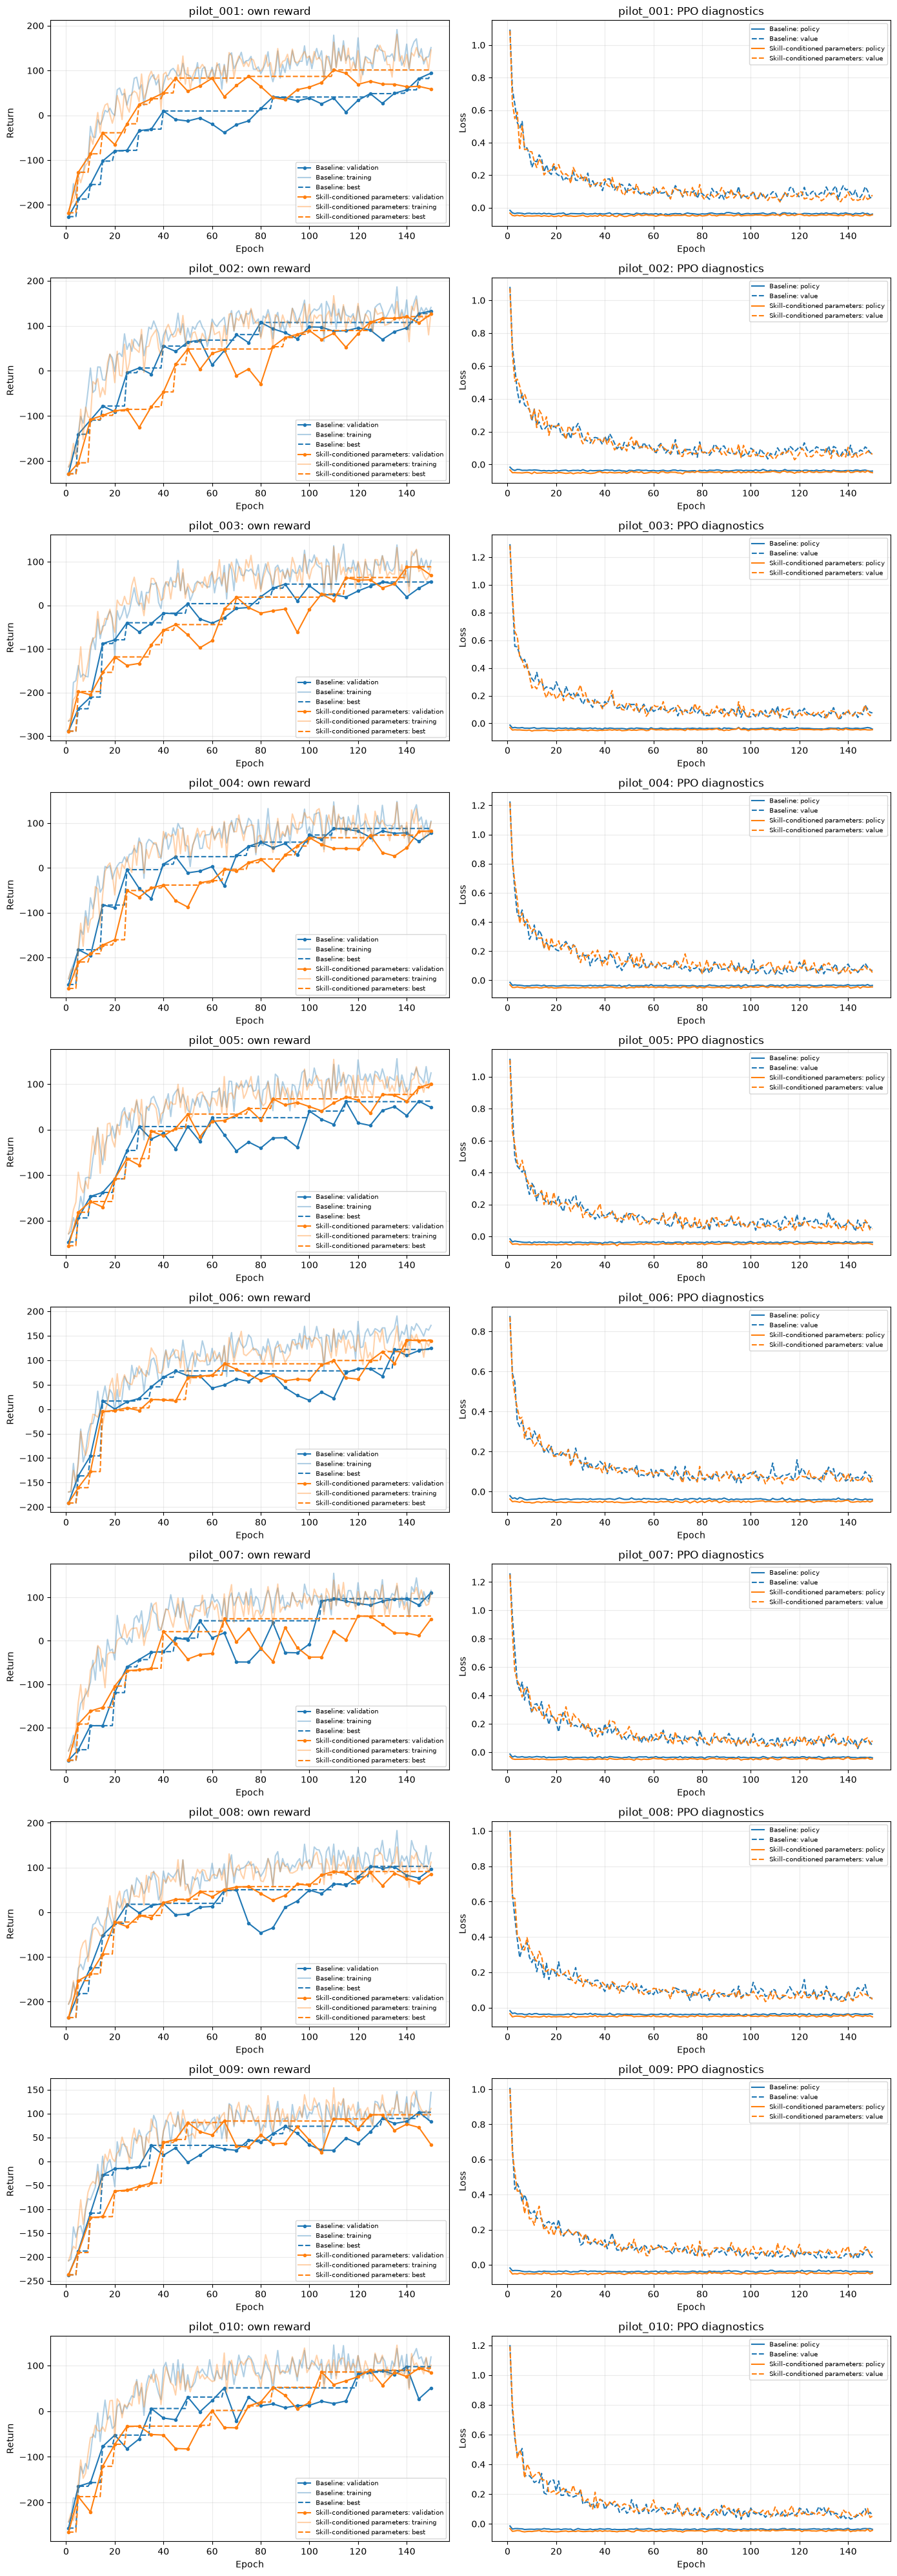

In [5]:
COLOURS = {"Baseline": "tab:blue", EXPERIMENT_LABEL: "tab:orange"}
pilot_ids = sorted({
    pilot_id for metrics in metrics_by_run.values()
    for pilot_id, frame in metrics.items() if not frame.empty
})
if pilot_ids:
    figure, axes = plt.subplots(len(pilot_ids), 2, figsize=(14, 4 * len(pilot_ids)), squeeze=False)
    for row, pilot_id in enumerate(pilot_ids):
        for name, records in metrics_by_run.items():
            metrics = records.get(pilot_id, pd.DataFrame())
            if metrics.empty:
                continue
            pilot_status = next(p["status"] for p in batches[name]["pilots"] if p["pilot_id"] == pilot_id)
            label = name
            if pilot_status != "completed":
                label += f" ({pilot_status}, epoch {int(metrics['epoch'].max())})"
            evaluated = metrics[metrics["evaluation_performed"] == 1]
            colour = COLOURS[name]
            axes[row, 0].plot(evaluated["epoch"], evaluated["mean_return"],
                              marker=".", color=colour, label=f"{label}: validation")
            axes[row, 0].plot(metrics["epoch"], metrics["training_mean_return"],
                              alpha=0.35, color=colour, label=f"{label}: training")
            axes[row, 0].plot(metrics["epoch"], metrics["best_return"],
                              linestyle="--", color=colour, label=f"{label}: best")
            if {"policy_loss", "value_loss"}.issubset(metrics.columns):
                axes[row, 1].plot(metrics["epoch"], metrics["policy_loss"],
                                  color=colour, label=f"{label}: policy")
                axes[row, 1].plot(metrics["epoch"], metrics["value_loss"],
                                  linestyle="--", color=colour, label=f"{label}: value")
            else:
                axes[row, 1].plot(metrics["epoch"], metrics["loss"], color=colour, label=label)
        axes[row, 0].set(title=f"{pilot_id}: own reward", xlabel="Epoch", ylabel="Return")
        axes[row, 1].set(title=f"{pilot_id}: PPO diagnostics", xlabel="Epoch", ylabel="Loss")
        for axis in axes[row]:
            axis.grid(alpha=0.25)
            axis.legend(fontsize=7)
    figure.tight_layout()
    show_plot(figure, "learning_curves")
else:
    print("No recorded epochs yet.")


## Original test plots

These show the same clean-win intervals and behaviour scatter as notebook 05, with both runs on the same axes. A missing bar is a pending result, not a zero clean-win rate. The Wilson intervals are per pilot and run; use the paired comparison below to assess changes on matching scenarios.


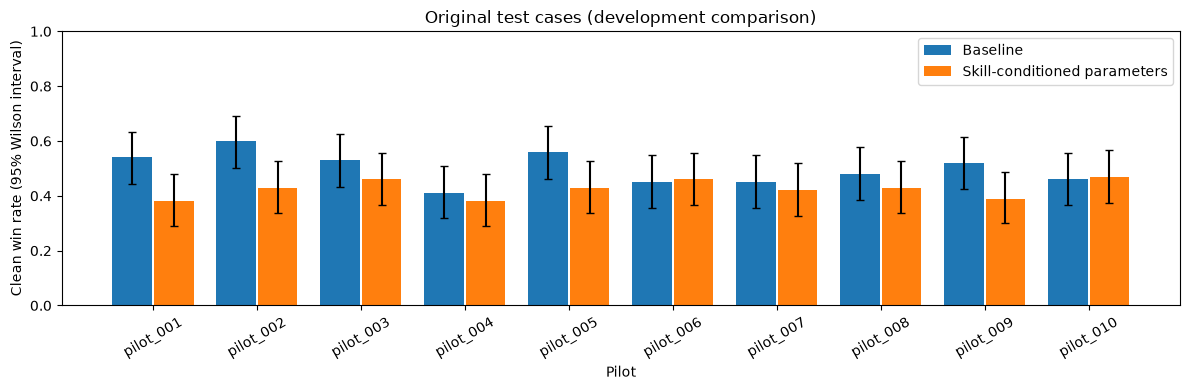

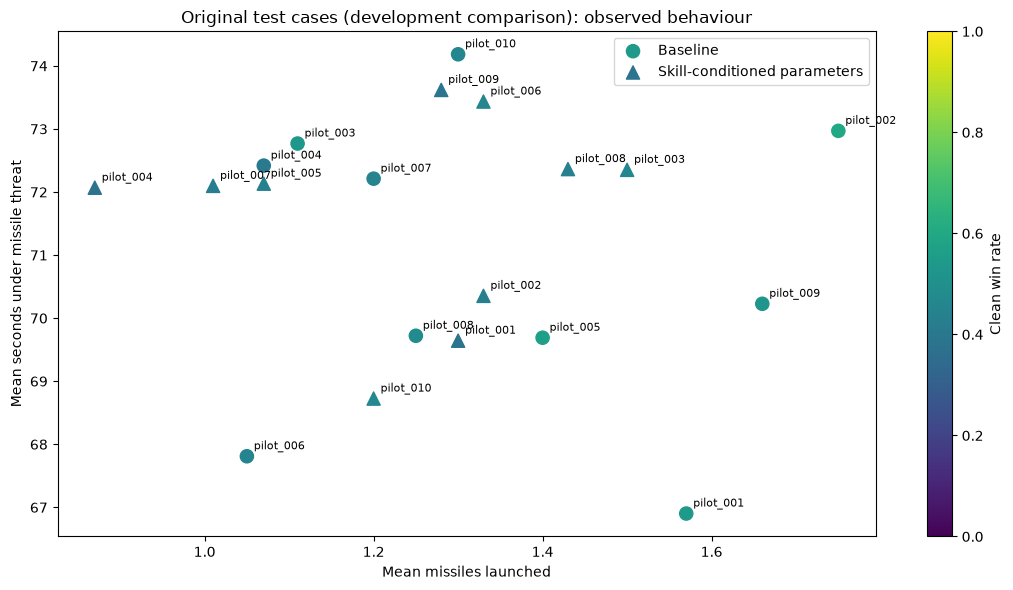

In [6]:
def plot_evaluation(frame, title, prefix):
    if frame.empty:
        print(f"{title}: no completed evaluations yet.")
        return
    pilot_ids = sorted(frame["pilot_id"].unique())
    positions = np.arange(len(pilot_ids))
    figure, axis = plt.subplots(figsize=(12, 4))
    for offset, (name, colour) in zip((-0.2, 0.2), COLOURS.items()):
        data = frame[frame["run"] == name]
        if data.empty:
            continue
        x = np.asarray([pilot_ids.index(pilot_id) for pilot_id in data["pilot_id"]])
        rate = data["clean_win_rate"].to_numpy()
        bounds = np.asarray(data["clean_win_ci95"].tolist())
        errors = np.maximum(0, np.vstack((rate - bounds[:, 0], bounds[:, 1] - rate)))
        axis.bar(x + offset, rate, width=0.38, yerr=errors, capsize=3, color=colour, label=name)
    axis.set(xticks=positions, xticklabels=pilot_ids, ylim=(0, 1), xlabel="Pilot",
             ylabel="Clean win rate (95% Wilson interval)", title=title)
    axis.tick_params(axis="x", labelrotation=30)
    axis.legend()
    figure.tight_layout()
    show_plot(figure, f"{prefix}_clean_wins")

    figure, axis = plt.subplots(figsize=(11, 6))
    points = None
    for name, marker in zip(COLOURS, ("o", "^")):
        data = frame[frame["run"] == name].dropna(
            subset=["mean_missiles_launched", "mean_threatened_seconds"]
        )
        if data.empty:
            continue
        points = axis.scatter(
            data["mean_missiles_launched"], data["mean_threatened_seconds"],
            c=data["clean_win_rate"], vmin=0, vmax=1, s=90, cmap="viridis",
            marker=marker, label=name,
        )
        for _, pilot in data.iterrows():
            axis.annotate(pilot["pilot_id"],
                          (pilot["mean_missiles_launched"], pilot["mean_threatened_seconds"]),
                          xytext=(5, 5), textcoords="offset points", fontsize=8)
    axis.set(title=f"{title}: observed behaviour",
             xlabel="Mean missiles launched", ylabel="Mean seconds under missile threat")
    if points is not None:
        figure.colorbar(points, ax=axis, label="Clean win rate")
        axis.legend()
    figure.tight_layout()
    show_plot(figure, f"{prefix}_behaviour")


plot_evaluation(test_summary, "Original test cases (development comparison)", "development")


## Fresh confirmation: the same evaluation tables and plots

After training, the runner evaluates **both populations** on the predeclared fresh scenarios. This section reads those results as they arrive. It uses the same outcome definitions, behaviour measurements and plots as above. Until both populations finish, these are partial results; the final population comparison appears in the next section.


Predeclared suite: {'seed': 820000, 'scenarios': 300}


,run,pilot_id,scenarios,clean_win_rate,clean_win_ci95,mutual_destruction_rate,survival_rate,elimination_rate,outcome_score
0,Baseline,pilot_001,300,0.640000,"[0.584229303230313, 0.6922306648268142]",0.206667,0.700000,0.846667,44.333333
1,Baseline,pilot_002,300,0.626667,"[0.5706551328853308, 0.6794753144044509]",0.216667,0.736667,0.843333,47.166667
4,Baseline,pilot_005,300,0.626667,"[0.5706551328853308, 0.6794753144044509]",0.210000,0.650000,0.836667,38.166667
8,Baseline,pilot_009,300,0.590000,"[0.5335482149789318, 0.6441760502006498]",0.226667,0.686667,0.816667,39.000000
7,Baseline,pilot_008,300,0.586667,"[0.5301906151568371, 0.6409512698309082]",0.243333,0.706667,0.830000,41.500000
2,Baseline,pilot_003,300,0.583333,"[0.5268355964602695, 0.6377239083356395]",0.203333,0.700000,0.786667,38.500000
6,Baseline,pilot_007,300,0.546667,"[0.49009847513929183, 0.6020548475464171]",0.196667,0.743333,0.743333,38.833333
9,Baseline,pilot_010,300,0.543333,"[0.48677384505565635, 0.5987970974382163]",0.173333,0.763333,0.716667,39.333333
3,Baseline,pilot_004,300,0.526667,"[0.4701880395241621, 0.5824710020105287]",0.193333,0.743333,0.720000,36.666667
5,Baseline,pilot_006,300,0.526667,"[0.4701880395241621, 0.5824710020105287]",0.143333,0.663333,0.670000,26.166667


,run,pilot_id,mean_missiles_launched,mean_missiles_avoided,mean_threatened_seconds,mean_duration_seconds
0,Baseline,pilot_001,1.563333,3.180000,67.758333,77.280667
1,Baseline,pilot_002,1.763333,3.466667,72.698667,83.538000
2,Baseline,pilot_003,1.106667,3.273333,69.759667,80.316000
3,Baseline,pilot_004,1.050000,3.306667,72.129333,83.519667
4,Baseline,pilot_005,1.376667,2.966667,69.010667,78.359333
5,Baseline,pilot_006,1.133333,3.010000,67.189333,79.803333
6,Baseline,pilot_007,1.196667,3.453333,71.869667,82.961667
7,Baseline,pilot_008,1.240000,3.173333,69.804333,81.275667
8,Baseline,pilot_009,1.480000,3.113333,70.445000,80.939000
9,Baseline,pilot_010,1.270000,3.516667,74.091667,84.759000


abort_support  beam_missile_left  \
run                          pilot_id                                      
Baseline                     pilot_001       0.000343           0.000558   
                             pilot_002       0.069138           0.000000   
                             pilot_003       0.000289           0.004008   
                             pilot_004       0.085835           0.000000   
                             pilot_005       0.000000           0.000000   
                             pilot_006       0.003866           0.000873   
                             pilot_007       0.000440           0.000000   
                             pilot_008       0.013758           0.000000   
                             pilot_009       0.007297           0.000000   
                             pilot_010       0.043516           0.000000   
Skill-conditioned parameters pilot_001       0.003750           0.000000   
                             pilot_002       0.001873           0.000000   
                             pilot_003       0.020948           0.002668   
                             pilot_004       0.000040           0.000000   
                             pilot_005       0.001437           0.000000   
                             pilot_006       0.027018           0.001603   
                             pilot_007       0.000000           0.000000   
                             pilot_008       0.026055           0.004487   
                             pilot_009       0.000000           0.000839   
                             pilot_010       0.042951           0.003961   

                                        beam_missile_right  beam_target_left  \
run                          pilot_id                                          
Baseline                     pilot_001            0.002359          0.084413   
                             pilot_002            0.004450          0.033576   
                             pilot_003            0.006859          0.013347   
                             pilot_004            0.007474          0.076929   
                             pilot_005            0.007194          0.025517   
                             pilot_006            0.000374          0.086461   
                             pilot_007            0.002882          0.046108   
                             pilot_008            0.007798          0.020249   
                             pilot_009            0.008363          0.095806   
                             pilot_010            0.000000          0.044221   
Skill-conditioned parameters pilot_001            0.000000          0.006358   
                             pilot_002            0.000000          0.067242   
                             pilot_003            0.004102          0.038192   
                             pilot_004            0.006522          0.009802   
                             pilot_005            0.000078          0.091336   
                             pilot_006            0.014191          0.082378   
                             pilot_007            0.000000          0.001499   
                             pilot_008            0.011178          0.087886   
                             pilot_009            0.000000          0.039035   
                             pilot_010            0.000167          0.102831   

                                        beam_target_right  crank_target_left  \
run                          pilot_id                                          
Baseline                     pilot_001           0.016514           0.169169   
                             pilot_002           0.109588           0.182660   
                             pilot_003           0.025908           0.124499   
                             pilot_004           0.042102           0.094899   
                             pilot_005           0.122974           0.205789   
                             pilot_006        

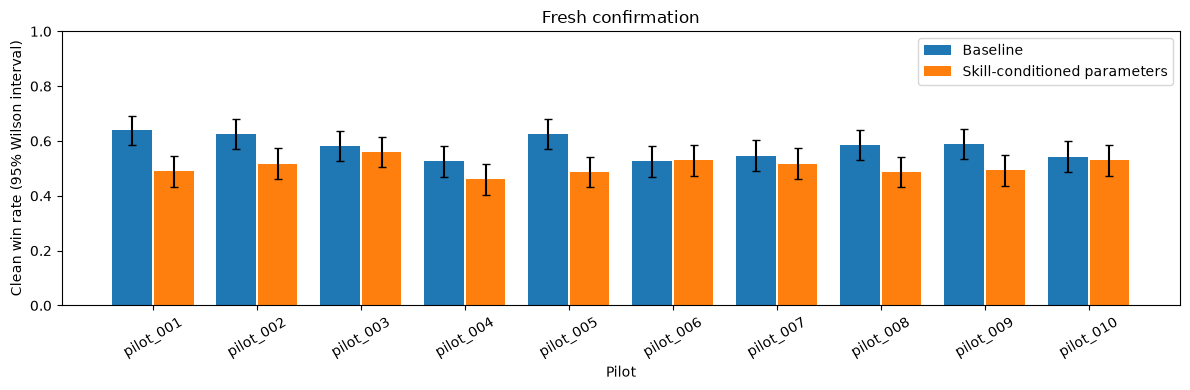

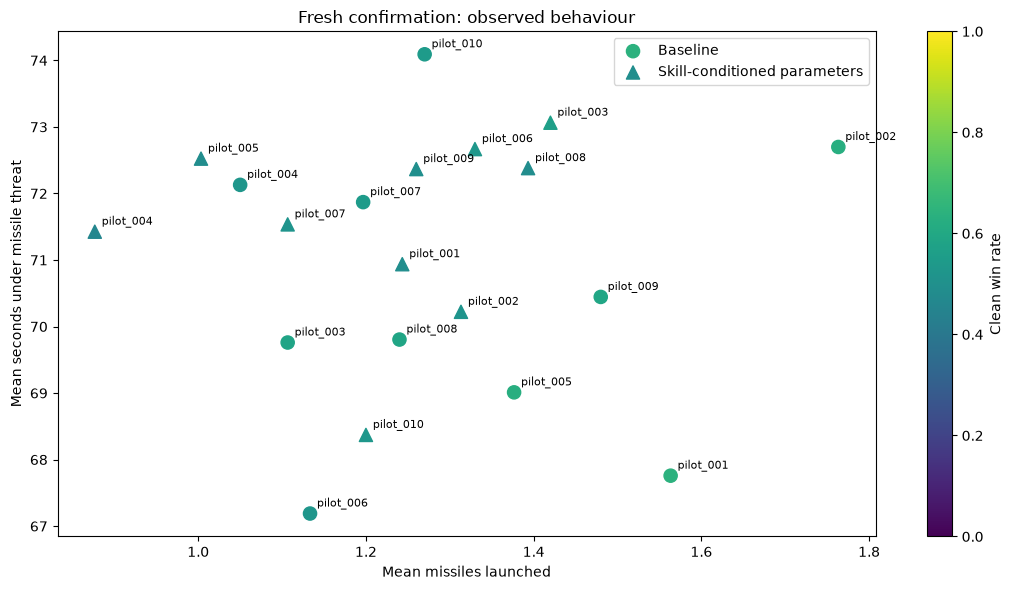

In [7]:
confirmation_rows = []
for population, name in (("baseline", "Baseline"), ("experiment", EXPERIMENT_LABEL)):
    for path in sorted((EXPERIMENT_JOB / "confirmation" / population).glob("*/evaluation.json")):
        evaluation = read_json(path)
        confirmation_rows.append({
            "run": name, "pilot_id": path.parent.name, **evaluation["summary"]
        })
confirmation_summary = pd.DataFrame(confirmation_rows)
print(f"Predeclared suite: {plan['confirmation']}")
show_competence(confirmation_summary)
show_behaviour(confirmation_summary)
plot_evaluation(confirmation_summary, "Fresh confirmation", "confirmation")


## Matched differences and overall result

The runner writes this comparison only after the relevant suite is complete for the whole population. The primary measure is the mean clean-win rate over all matching reward profiles, not the best pilot. Gained/lost wins count identical cases whose clean-win outcome changed.

The paired bootstrap resamples scenarios jointly across pilots; its interval measures scenario uncertainty. One training seed does not establish a robust improvement. Judge the fresh confirmation alongside survival and mutual destruction; do not select a checkpoint using it.


In [8]:
comparison_path = EXPERIMENT_JOB / "comparison.json"
if comparison_path.exists():
    comparison = read_json(comparison_path)
    aggregate_rows = []
    for suite, title in (
        ("existing_test", "Original test (development)"),
        ("fresh_confirmation", "Fresh confirmation"),
    ):
        if suite not in comparison:
            continue
        values = comparison[suite]
        display(Markdown(f"**{title}: paired changes**"))
        display(pd.DataFrame(values["pilots"]))
        aggregate_rows.append({
            "suite": title,
            "baseline_mean_clean_win_rate": values["baseline_mean_clean_win_rate"],
            "experiment_mean_clean_win_rate": values["experiment_mean_clean_win_rate"],
            "change_percentage_points": values["difference_percentage_points"],
            "paired_change_ci95_percentage_points":
                values["paired_scenario_bootstrap_ci95_percentage_points"],
        })
    display(pd.DataFrame(aggregate_rows))
    print(f"Report status: {comparison['status']}")
    print(f"Standalone report: {EXPERIMENT_JOB / 'comparison.html'}")
else:
    print("The full-population comparison will appear after all pilots finish training and testing.")
if "bounded_decision_criteria" in plan:
    display(Markdown("**Predeclared bounded experiment criteria**"))
    display(pd.Series(plan["bounded_decision_criteria"], name="criterion"))
    if comparison_path.exists() and "decision" in comparison:
        display(Markdown("**Final confirmation decision**"))
        decision = comparison["decision"]
        display(pd.Series(decision["checks"], name="passed"))
        print(decision["recommendation"])
        print(decision["limitation"])
    else:
        print("Decision pending: both populations must finish all fresh confirmation cases.")

print("Save this notebook after refreshing to retain the displayed tables and embedded figures.")


**Original test (development): paired changes**

,pilot_id,scenarios,baseline_clean_win_rate,experiment_clean_win_rate,difference_percentage_points,gained_clean_wins,lost_clean_wins,baseline_survival_rate,experiment_survival_rate,baseline_mutual_destruction_rate,experiment_mutual_destruction_rate
0,pilot_001,100,0.54,0.38,-16.0,3,19,0.64,0.62,0.27,0.26
1,pilot_002,100,0.60,0.43,-17.0,1,18,0.73,0.69,0.23,0.23
2,pilot_003,100,0.53,0.46,-7.0,3,10,0.73,0.72,0.21,0.23
3,pilot_004,100,0.41,0.38,-3.0,3,6,0.70,0.68,0.23,0.24
4,pilot_005,100,0.56,0.43,-13.0,4,17,0.67,0.71,0.20,0.21
5,pilot_006,100,0.45,0.46,1.0,7,6,0.63,0.71,0.14,0.22
6,pilot_007,100,0.45,0.42,-3.0,1,4,0.71,0.67,0.23,0.23
7,pilot_008,100,0.48,0.43,-5.0,7,12,0.66,0.67,0.27,0.21
8,pilot_009,100,0.52,0.39,-13.0,0,13,0.67,0.69,0.23,0.23
9,pilot_010,100,0.46,0.47,1.0,4,3,0.74,0.67,0.21,0.23


**Fresh confirmation: paired changes**

,pilot_id,scenarios,baseline_clean_win_rate,experiment_clean_win_rate,difference_percentage_points,gained_clean_wins,lost_clean_wins,baseline_survival_rate,experiment_survival_rate,baseline_mutual_destruction_rate,experiment_mutual_destruction_rate
0,pilot_001,300,0.640000,0.490000,-15.000000,6,51,0.700000,0.700000,0.206667,0.230000
1,pilot_002,300,0.626667,0.516667,-11.000000,7,40,0.736667,0.713333,0.216667,0.200000
2,pilot_003,300,0.583333,0.560000,-2.333333,15,22,0.700000,0.746667,0.203333,0.200000
3,pilot_004,300,0.526667,0.460000,-6.666667,5,25,0.743333,0.723333,0.193333,0.210000
4,pilot_005,300,0.626667,0.486667,-14.000000,11,53,0.650000,0.740000,0.210000,0.200000
5,pilot_006,300,0.526667,0.530000,0.333333,25,24,0.663333,0.720000,0.143333,0.216667
6,pilot_007,300,0.546667,0.516667,-3.000000,2,11,0.743333,0.703333,0.196667,0.200000
7,pilot_008,300,0.586667,0.486667,-10.000000,18,48,0.706667,0.733333,0.243333,0.180000
8,pilot_009,300,0.590000,0.493333,-9.666667,4,33,0.686667,0.720000,0.226667,0.213333
9,pilot_010,300,0.543333,0.530000,-1.333333,11,15,0.763333,0.693333,0.173333,0.236667


,suite,baseline_mean_clean_win_rate,experiment_mean_clean_win_rate,change_percentage_points,paired_change_ci95_percentage_points
0,Original test (development),0.500000,0.425,-7.500000,"[-10.999999999999998, -4.3]"
1,Fresh confirmation,0.579667,0.507,-7.266667,"[-9.233333333333334, -5.532500000000003]"


...

**Predeclared bounded experiment criteria**

minimum_clean_win_gain_percentage_points                                                               3.0
minimum_ci_lower_bound_percentage_points_exclusive                                                     0.0
maximum_survival_drop_percentage_points                                                                2.0
maximum_mutual_destruction_increase_percentage_points                                                  2.0
training_runs_per_profile                                                                                1
next_step                                                Review this one comparison, then choose a popu...
Name: criterion, dtype: object

**Final confirmation decision**

clean_win_gain               False
positive_paired_interval     False
survival_margin               True
mutual_destruction_margin     True
Name: passed, dtype: bool

Retain the selected-skill baseline for tactical adaptation review.
One training seed per profile; intervals describe scenario uncertainty only. Safety margins use point estimates.
Save this notebook after refreshing to retain the displayed tables and embedded figures.


## Population outcomes and paired improvements

The stacked bars partition every flight into one of four outcomes. Population averages give each pilot equal weight. Compare populations **within** each suite; the two suites contain different scenarios.

The paired-change charts show which pilots improve or regress on the same cases. The interval in each title is for the **population mean change**, from the recorded paired scenario bootstrap. It does not measure variation across training seeds. Positive changes mean more clean wins; these plots do not select checkpoints.

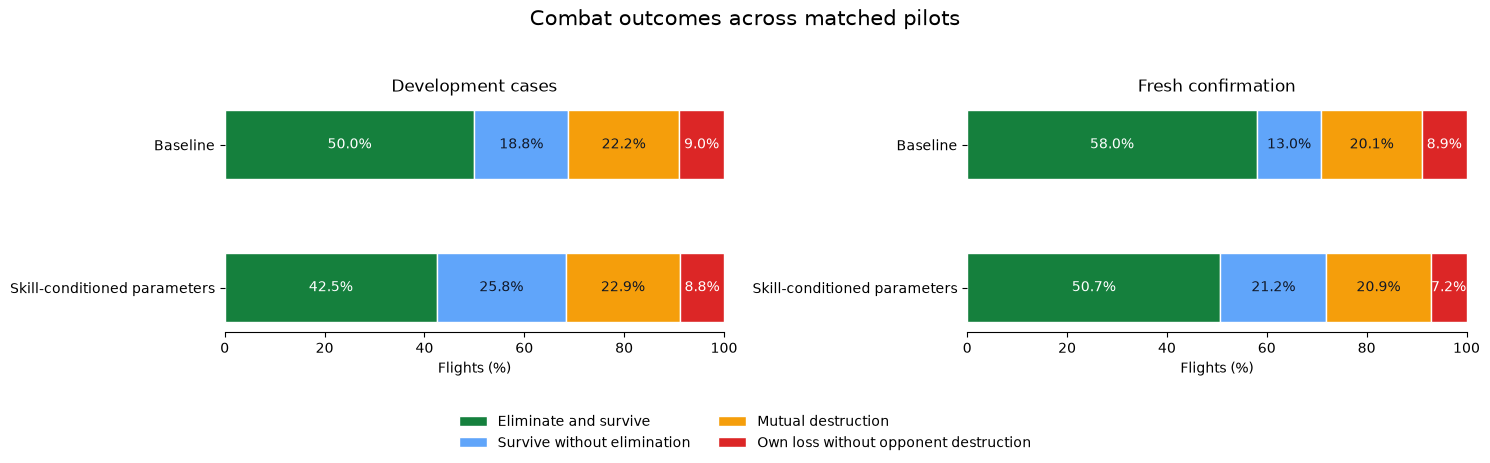

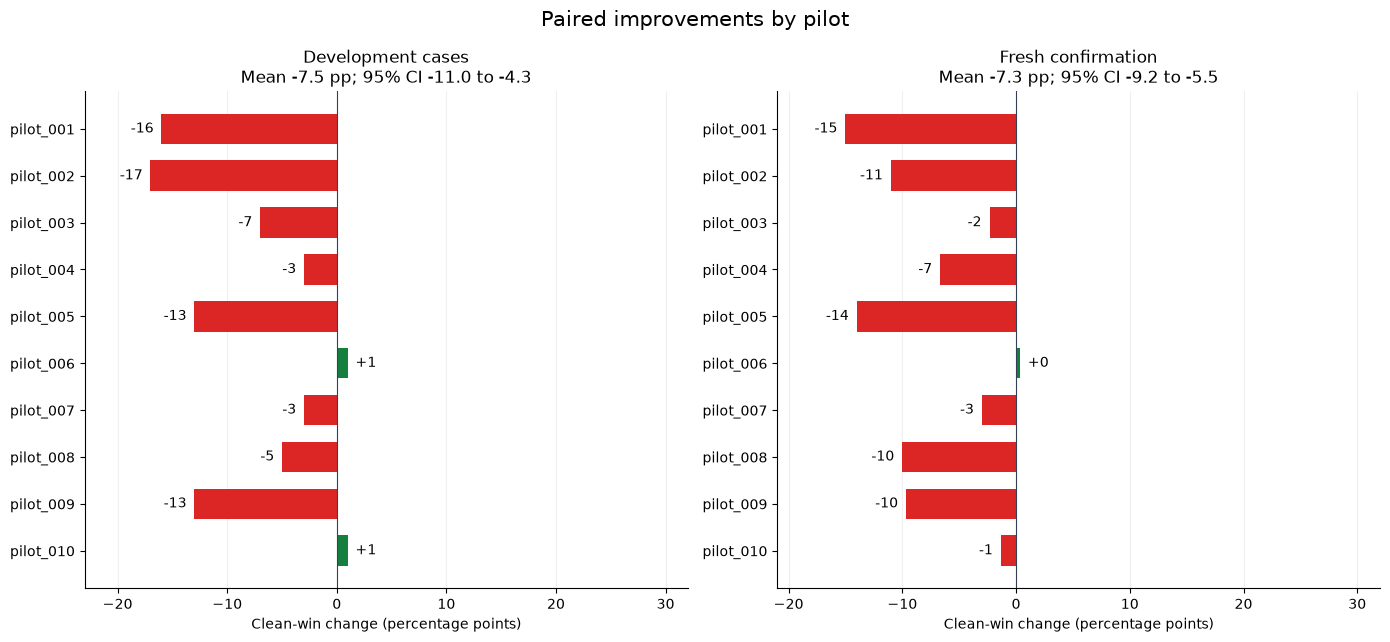

In [9]:
if comparison_path.exists() and comparison.get("status") == "completed":
    suites = [
        ("existing_test", "Development cases", test_summary),
        ("fresh_confirmation", "Fresh confirmation", confirmation_summary),
    ]
    outcomes = [
        ("clean_win_rate", "Eliminate and survive", "#15803d", "white"),
        ("survived_without_elimination_rate", "Survive without elimination", "#60a5fa", "#111827"),
        ("mutual_destruction_rate", "Mutual destruction", "#f59e0b", "#111827"),
        ("loss_without_elimination_rate", "Own loss without opponent destruction", "#dc2626", "white"),
    ]
    figure, axes = plt.subplots(1, 2, figsize=(15, 4.6))
    for axis, (key, title, frame) in zip(axes, suites):
        columns = [item[0] for item in outcomes]
        assert np.allclose(frame[columns].sum(axis=1), 1.0)
        means = frame.groupby("run")[columns].mean().reindex(list(RUNS)) * 100
        left = np.zeros(len(means))
        for column, label, colour, text_colour in outcomes:
            values = means[column].to_numpy()
            axis.barh(np.arange(len(means)), values, left=left, color=colour,
                      label=label, height=0.48, edgecolor="white")
            for row, value in enumerate(values):
                axis.text(left[row] + value / 2, row, f"{value:.1f}%",
                          ha="center", va="center", color=text_colour, fontsize=10)
            left += values
        axis.set(yticks=np.arange(len(means)), yticklabels=means.index,
                 xlim=(0, 100), xlabel="Flights (%)", title=title)
        axis.invert_yaxis()
        axis.spines[["top", "right", "left"]].set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
    figure.suptitle("Combat outcomes across matched pilots", fontsize=15)
    figure.tight_layout(rect=(0, 0.15, 1, 0.94))
    show_plot(figure, "population_outcomes")

    figure, axes = plt.subplots(1, 2, figsize=(14, 6.5))
    for axis, (key, title, _) in zip(axes, suites):
        result = comparison[key]
        changes = pd.DataFrame(result["pilots"]).sort_values("pilot_id")
        values = changes["difference_percentage_points"].to_numpy()
        colours = ["#15803d" if v > 0 else "#dc2626" if v < 0 else "#64748b" for v in values]
        axis.barh(changes["pilot_id"], values, color=colours, height=0.65)
        for row, value in enumerate(values):
            axis.text(value + (0.7 if value >= 0 else -0.7), row, f"{value:+.0f}",
                      va="center", ha="left" if value >= 0 else "right")
        low, high = result["paired_scenario_bootstrap_ci95_percentage_points"]
        axis.axvline(0, color="#334155", linewidth=0.8)
        axis.set(xlim=(min(-12, values.min() - 6), max(32, values.max() + 6)),
                 xlabel="Clean-win change (percentage points)",
                 title=f"{title}\nMean {result['difference_percentage_points']:+.1f} pp; 95% CI {low:+.1f} to {high:+.1f}")
        axis.invert_yaxis()
        axis.grid(axis="x", alpha=0.2)
        axis.set_axisbelow(True)
        axis.spines[["top", "right"]].set_visible(False)
    figure.suptitle("Paired improvements by pilot", fontsize=15)
    figure.tight_layout()
    show_plot(figure, "paired_clean_win_changes")
else:
    print("These summary plots appear when the full comparison is complete.")
